# Parte Comum — Padronização, K-Means e Métricas (Wine Quality)
Projeto Final AVD 2026.2 — Grupo 6.

Fonte: Cortez et al. (2009), Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, 47(4), 547–553. https://doi.org/10.1016/j.dss.2009.05.016

Responsável original: **Sacramento**. Colaboração na complementação: **Arthur Borges**.

## Configuração

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
candidates = [Path.cwd(), *Path.cwd().parents]
DATA = next((r / 'data/parte_comum/wine_quality/winequality-combined.csv' for r in candidates if (r / 'data/parte_comum/wine_quality/winequality-combined.csv').is_file()), None)
if DATA is None:
    DATA = next((r / 'winequality-combined.csv' for r in candidates if (r / 'winequality-combined.csv').is_file()), None)
if DATA is None:
    raise FileNotFoundError('Coloque winequality-combined.csv em data/parte_comum/wine_quality/')
ROOT = DATA.parents[3] if DATA.parent.name == 'wine_quality' else DATA.parent
OUT = ROOT / 'out/parte_comum/wine_quality'
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA, sep=';')
coluna_classe = 'quality'
num = df.select_dtypes(include='number').columns.drop(coluna_classe).tolist()
sns.set_theme(style='whitegrid')
def salvar(nome):
    plt.tight_layout()
    plt.savefig(OUT / nome, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
print(DATA, df.shape)

c:\Users\Samsung\OneDrive\Documentos\GitHub\projeto-avd-2026-2-pump-it-up-classificatorio\data\parte_comum\wine_quality\winequality-combined.csv (6497, 13)


## 1. Preparação e padronização

In [ ]:
# [IA] ChatGPT – apoio com pandas/scikit-learn e implementação
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, silhouette_score, davies_bouldin_score
# Configuração inicial: manter registros e incluir tipo como indicador binário.
REMOVER_DUPLICATAS = False
INCLUIR_TIPO = True
if REMOVER_DUPLICATAS: df=df.drop_duplicates().reset_index(drop=True)
X=df[num].copy()
if INCLUIR_TIPO: X['wine_type_red'] = df.wine_type.eq('red').astype(int)
y=df.quality.reset_index(drop=True)
Z=StandardScaler().fit_transform(X)
classes=sorted(y.unique())
pca=PCA(n_components=2,random_state=42)
coords=pca.fit_transform(Z)
print('Classes:',classes,'Variância PCA:',pca.explained_variance_ratio_)

Classes: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)] Variância PCA: [0.3174498  0.21072897]


A nota quality foi excluída das entradas para evitar que os rótulos orientem o agrupamento. A padronização coloca atributos com unidades distintas em escalas comparáveis. O tipo de vinho foi incluído como indicador binário padronizado, podendo influenciar a separação dos grupos. Foram mantidos os registros duplicados e valores atípicos, em conformidade com a EDA.

## 2. Passada 1 — k livre (Método do Cotovelo)

,k,inercia,silhouette,davies_bouldin,reducao_percentual
0,2,56403.476541,0.335444,1.335601,NaN
1,3,45875.739036,0.252266,1.419573,18.665051
2,4,41190.132497,0.251817,1.481230,10.213692
3,5,38471.552554,0.182685,1.799612,6.600076
4,6,36356.034008,0.186258,1.662378,5.498916
5,7,34418.178959,0.182218,1.597726,5.330216
6,8,33092.248132,0.162486,1.687326,3.852414
7,9,31945.039268,0.143029,1.766083,3.466700
8,10,30958.047193,0.141592,1.759622,3.089657


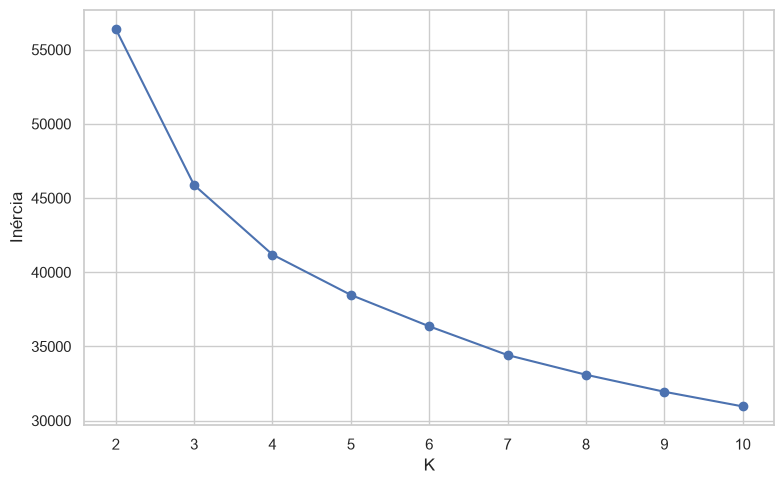

In [4]:
# [IA] ChatGPT – apoio com pandas/scikit-learn e implementação
modelos={}; linhas=[]
for k in range(2,11):
    m=KMeans(n_clusters=k,random_state=42,n_init=10).fit(Z)
    modelos[k]=m
    linhas.append({'k':k,'inercia':m.inertia_,'silhouette':silhouette_score(Z,m.labels_,sample_size=min(2000,len(Z)),random_state=42),'davies_bouldin':davies_bouldin_score(Z,m.labels_)})
avaliacao=pd.DataFrame(linhas)
avaliacao['reducao_percentual']= -avaliacao.inercia.pct_change()*100
display(avaliacao); avaliacao.to_csv(OUT/'avaliacao_clusters.csv',index=False)
plt.figure(figsize=(8,5)); plt.plot(avaliacao.k,avaliacao.inercia,marker='o'); plt.xticks(avaliacao.k); plt.xlabel('K'); plt.ylabel('Inércia'); salvar('metodo_cotovelo.png')

Após k = 3 a diferença gradual vai diminuindo significativamente, portanto foi escolhido k = 3.

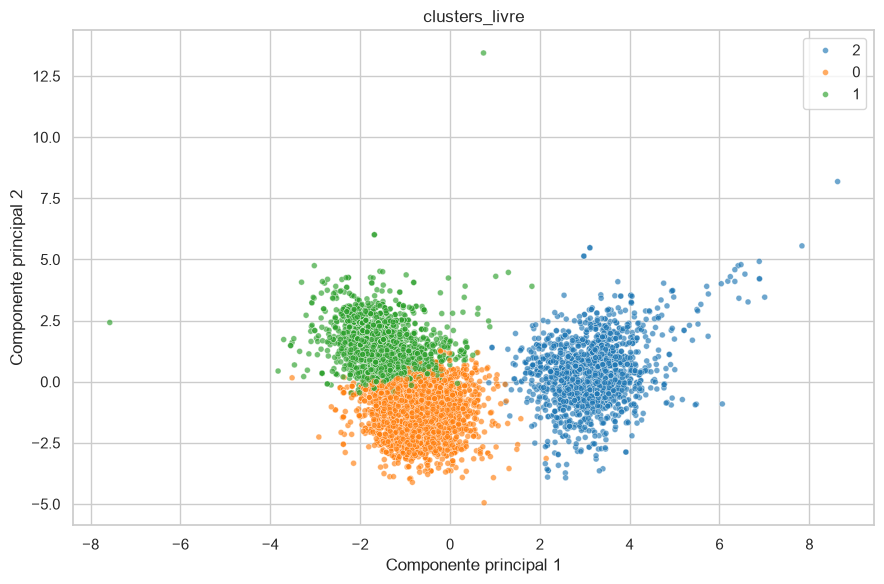

In [11]:
# [IA] ChatGPT – apoio com pandas/scikit-learn e implementação
K_LIVRE = 3
if K_LIVRE not in modelos: raise ValueError('Escolha K_LIVRE entre 2 e 10 após analisar o cotovelo.')
K_FIXO=len(classes)
livre=modelos[K_LIVRE]
def visualizar(modelo,nome):
    plt.figure(figsize=(9,6)); sns.scatterplot(x=coords[:,0],y=coords[:,1],hue=modelo.labels_.astype(str),palette='tab10',s=18,alpha=.65); plt.xlabel('Componente principal 1'); plt.ylabel('Componente principal 2'); plt.title(nome); salvar(nome+'.png')
visualizar(livre,'clusters_livre')

## 3. Passada 2 — k fixo

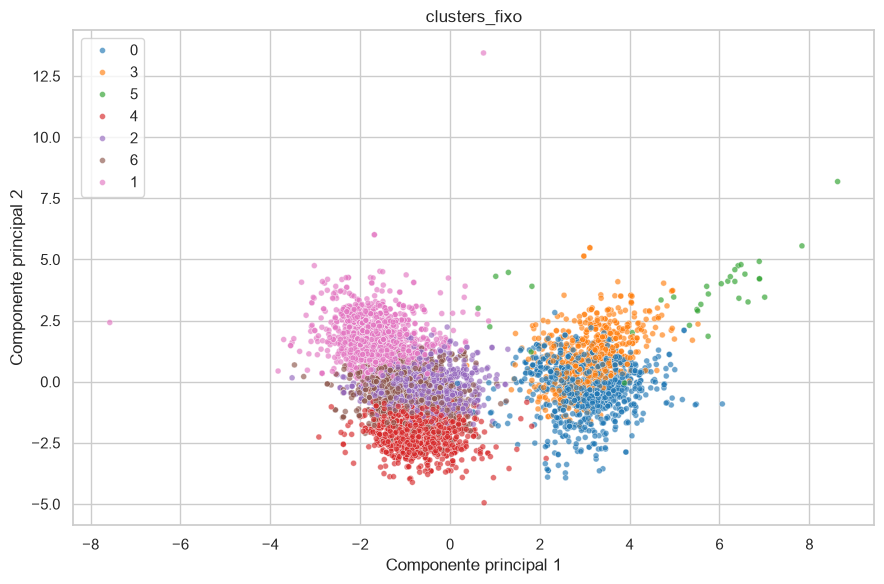

In [6]:
# [IA] ChatGPT – apoio com pandas/scikit-learn e implementação
fixo=KMeans(n_clusters=K_FIXO,random_state=42,n_init=10).fit(Z)
visualizar(fixo,'clusters_fixo')

O k fixo é 7, correspondente às notas de 3 a 9. A inércia cai para 34.418,18, mas a Silhouette diminui para 0,1822 e Davies-Bouldin aumenta para 1,5977 em relação a k=2. A redução da inércia é esperada com mais centros e não demonstra, isoladamente, melhor agrupamento. O PCA é apenas uma projeção para visualização.

## 4. Mapeamento cluster → classe majoritária

In [7]:
# [IA] ChatGPT – apoio com pandas/scikit-learn e implementação
def mapear(modelo,nome):
    tabela=pd.crosstab(pd.Series(modelo.labels_,name='cluster'),y.rename('quality')).reindex(columns=classes,fill_value=0)
    display(tabela); tabela.to_csv(OUT/f'matriz_cluster_classe_{nome}.csv')
    mapa=tabela.idxmax(axis=1)
    print(mapa)
    return pd.Series(modelo.labels_).map(mapa)
pred_livre=mapear(livre,'livre'); pred_fixo=mapear(fixo,'fixo')

quality,3,4,5,6,7,8,9
cluster,,,,,,,
0,11,57,683,632,196,18,0
1,19,159,1455,2204,883,175,5


cluster
0    5
1    6
dtype: int64


quality,3,4,5,6,7,8,9
cluster,,,,,,,
0,7,46,470,356,50,5,0
1,8,26,650,644,122,21,1
2,5,77,416,513,130,27,0
3,3,10,199,265,144,13,0
4,4,21,82,541,454,97,4
5,1,2,20,9,1,0,0
6,2,34,301,508,178,30,0


cluster
0    5
1    5
2    6
3    6
4    6
5    5
6    6
dtype: int64


## 5. Matriz de confusão e métricas

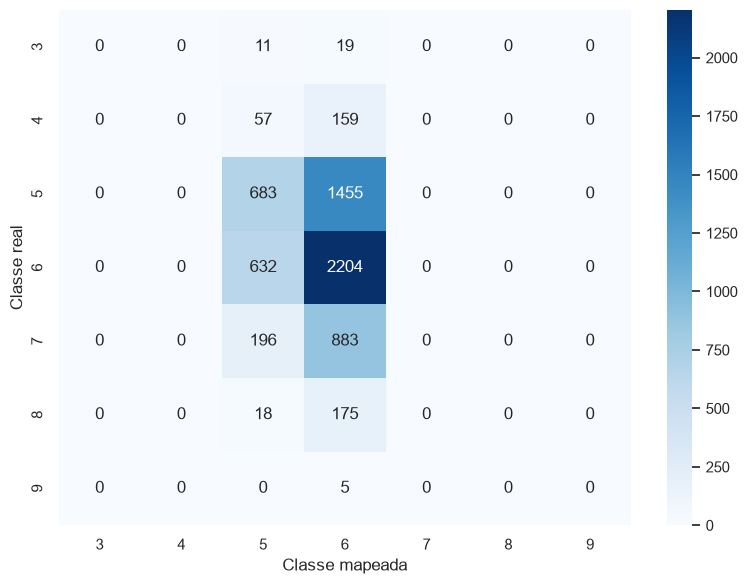

,precision,recall,f1-score,support
3,0.000000,0.000000,0.000000,30.000000
4,0.000000,0.000000,0.000000,216.000000
5,0.427677,0.319457,0.365730,2138.000000
6,0.449796,0.777151,0.569804,2836.000000
7,0.000000,0.000000,0.000000,1079.000000
8,0.000000,0.000000,0.000000,193.000000
9,0.000000,0.000000,0.000000,5.000000
accuracy,0.444359,0.444359,0.444359,0.444359
macro avg,0.125353,0.156658,0.133648,6497.000000
weighted avg,0.337078,0.444359,0.369077,6497.000000


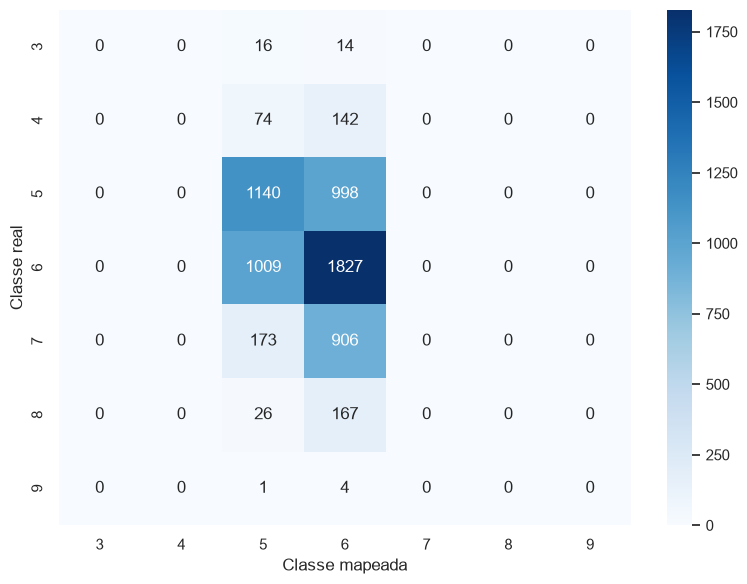

,precision,recall,f1-score,support
3,0.000000,0.000000,0.000000,30.000000
4,0.000000,0.000000,0.000000,216.000000
5,0.467405,0.533209,0.498143,2138.000000
6,0.450222,0.644217,0.530026,2836.000000
7,0.000000,0.000000,0.000000,1079.000000
8,0.000000,0.000000,0.000000,193.000000
9,0.000000,0.000000,0.000000,5.000000
accuracy,0.456672,0.456672,0.456672,0.456672
macro avg,0.131089,0.168204,0.146881,6497.000000
weighted avg,0.350337,0.456672,0.395288,6497.000000


,passada,k,inercia,acuracia,precision_macro,recall_macro,f1-score_macro
0,livre,2,56403.476541,0.444359,0.125353,0.156658,0.133648
1,fixo,7,34418.178959,0.456672,0.131089,0.168204,0.146881


In [8]:
# [IA] ChatGPT – apoio com pandas/scikit-learn e implementação
def avaliar(modelo,pred,nome):
    cm=pd.DataFrame(confusion_matrix(y,pred,labels=classes),index=classes,columns=classes)
    cm.to_csv(OUT/f'matriz_confusao_classes_{nome}.csv')
    plt.figure(figsize=(8,6)); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues'); plt.xlabel('Classe mapeada'); plt.ylabel('Classe real'); salvar(f'matriz_confusao_{nome}.png')
    rel=classification_report(y,pred,labels=classes,output_dict=True,zero_division=0)
    tabela=pd.DataFrame(rel).T; display(tabela); tabela.to_csv(OUT/f'metricas_{nome}.csv')
    return {'passada':nome,'k':modelo.n_clusters,'inercia':modelo.inertia_,'acuracia':accuracy_score(y,pred),**{f'{m}_macro':rel['macro avg'][m] for m in ['precision','recall','f1-score']}}
comparacao=pd.DataFrame([avaliar(livre,pred_livre,'livre'),avaliar(fixo,pred_fixo,'fixo')]); display(comparacao); comparacao.to_csv(OUT/'comparacao_passadas.csv',index=False)

Após o mapeamento por maioria, a acurácia passa de 44,44% (k=2) para 45,67% (k=7), ganho de 1,23 ponto percentual. O F1 macro passa de 0,1336 para 0,1469. Em ambas as passadas, apenas as notas 5 e 6 são atribuídas aos clusters; as demais têm recall zero. A classe 6 sozinha representa 43,65% da base, o que contextualiza a pequena vantagem da acurácia obtida. As métricas são calculadas na própria base agrupada, não em teste independente.

## 6. Discussão crítica

A passada com dois grupos apresenta melhores indicadores internos de separação, enquanto a de sete grupos tem uma concordância ligeiramente maior com as notas originais. As sete notas não necessariamente correspondem a sete grupos naturais: a qualidade é ordinal, as classes são desbalanceadas e atributos físico-químicos podem ser semelhantes entre notas próximas. A inclusão do tipo de vinho também pode favorecer agrupamentos por composição em vez de qualidade. Uma análise adicional sem esse indicador permitiria avaliar sua influência. Os resultados não justificam afirmar que o K-Means substitui um classificador supervisionado.